# WEEK 3 — LAB 1B: CONVOLUTION, CORRELATION AND DIFFERENCE EQUATIONS

## PRE-LAB QUESTIONS

### Question 1(a): Linear Convolution

Given:

- x(n) = {1, -1, 2}
- h(n) = {2, 1, 0, 1}

The linear convolution is calculated using:

y(n) = x(n) * h(n)

Calculations:

- y(0) = 1(2) = 2
- y(1) = 1(1) + (-1)(2) = -1
- y(2) = 1(0) + (-1)(1) + 2(2) = 3
- y(3) = 1(1) + (-1)(0) + 2(1) = 3
- y(4) = (-1)(1) + 2(0) = -1
- y(5) = 2(1) = 2

Therefore, the final convolution result is:

**y(n) = {2, -1, 3, 3, -1, 2}**

The output contains 6 samples because the length of the convolution output is L + M - 1 = 3 + 4 - 1 = 6.

### Question 1(b): Time Invariance

Given the system:

y(n) = n x(n)

This system is **not time-invariant**. It is a time-varying system because the output depends on the time index n.

To test time invariance:

1. Original input: x(n)

   Original output:

   y(n) = n x(n)

2. Shift the input by n₀:

   x(n - n₀)

   The output becomes:

   y₁(n) = n x(n - n₀)

3. Shift the original output by n₀:

   y(n - n₀) = (n - n₀)x(n - n₀)

The two outputs are generally not equal:

n x(n - n₀) ≠ (n - n₀)x(n - n₀)

Therefore, the system is **time-varying (not time-invariant)**.

In [1]:
import numpy as np
import time

# Function to calculate linear convolution
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)

    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]

    return y


# Test convolution using our function
x = [1, 2, 3, 1]
h = [1, 1, 1]

result1 = conv(x, h)
result2 = np.convolve(x, h)

print("Convolution using our function:")
print(result1)

print("\nConvolution using NumPy:")
print(result2)

print("\nAre the results equal?")
print(np.allclose(result1, result2))


# Compare execution time using random signals
rng = np.random.default_rng(0)

x_random = rng.standard_normal(2000)
h_random = rng.standard_normal(2000)

# Time our convolution function
start = time.perf_counter()
conv(x_random, h_random)
time_custom = time.perf_counter() - start

# Time NumPy convolution
start = time.perf_counter()
np.convolve(x_random, h_random)
time_numpy = time.perf_counter() - start

print("\nEXECUTION TIME COMPARISON")
print("Our function:", time_custom, "seconds")
print("NumPy function:", time_numpy, "seconds")

print("\nNumPy is faster:", time_numpy < time_custom)

Convolution using our function:
[1. 3. 6. 6. 4. 1.]

Convolution using NumPy:
[1 3 6 6 4 1]

Are the results equal?
True

EXECUTION TIME COMPARISON
Our function: 6.943393620999984 seconds
NumPy function: 0.003081804000032662 seconds

NumPy is faster: True


### Observation

The convolution function was successfully implemented using nested for loops.

The results obtained from our custom convolution function were the same as those obtained using NumPy's `np.convolve()` function.

The comparison returned True, confirming that both methods produce equal results.

The execution time comparison showed that NumPy performs convolution faster than the custom function. This is because NumPy uses optimized numerical operations, while the custom function performs calculations using Python loops.

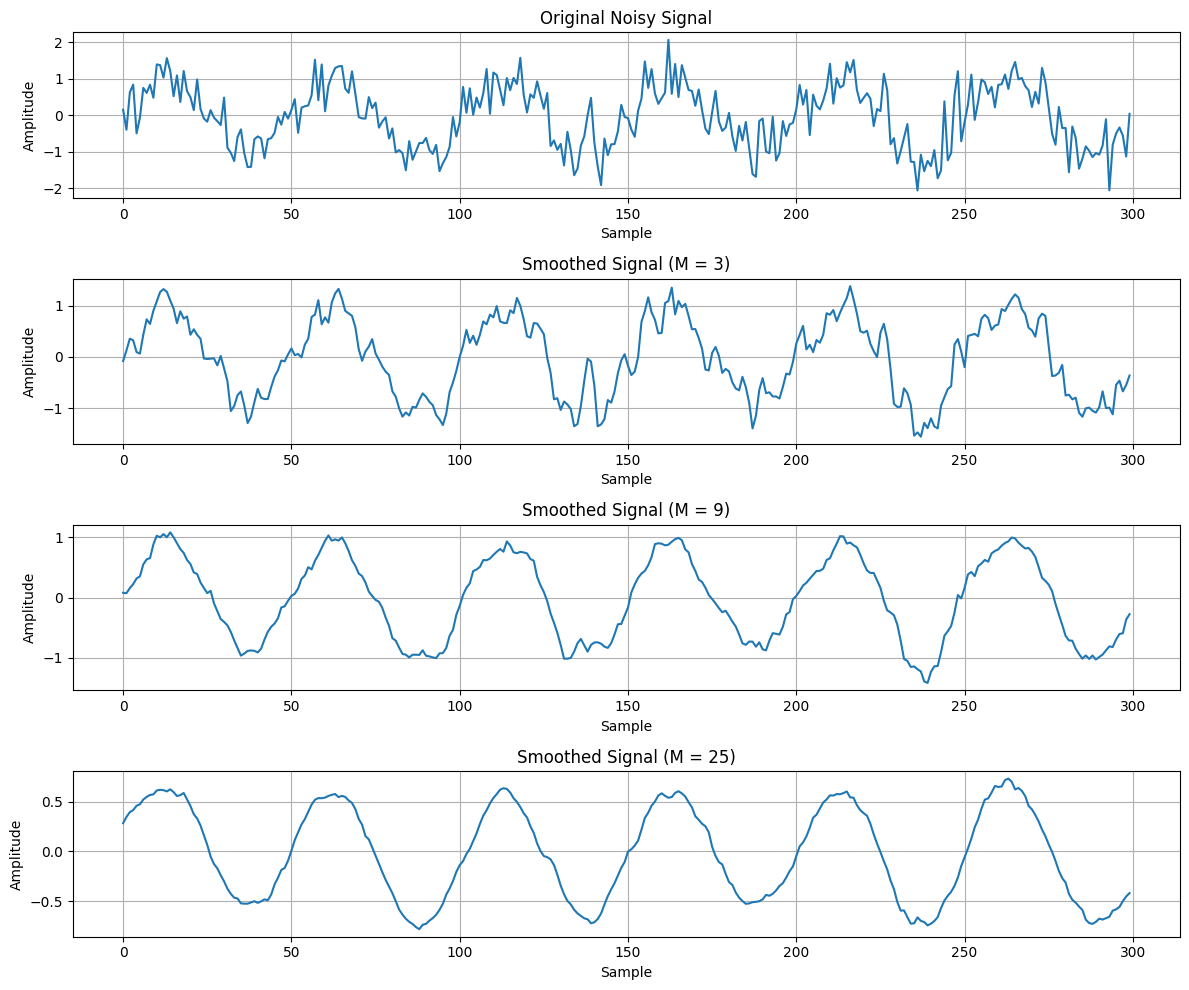

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Generate a noisy signal
rng = np.random.default_rng(42)

n = np.arange(300)
x = np.sin(2 * np.pi * n / 50) + 0.5 * rng.standard_normal(300)

# Moving average filters
M_values = [3, 9, 25]

plt.figure(figsize=(12, 10))

# Plot original noisy signal
plt.subplot(4, 1, 1)
plt.plot(n, x)
plt.title("Original Noisy Signal")
plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.grid()

# Apply and plot each moving average filter
for i, M in enumerate(M_values):
    h = np.ones(M) / M
    y = np.convolve(x, h, mode="same")

    plt.subplot(4, 1, i + 2)
    plt.plot(n, y)
    plt.title(f"Smoothed Signal (M = {M})")
    plt.xlabel("Sample")
    plt.ylabel("Amplitude")
    plt.grid()

plt.tight_layout()
plt.show()

### Observation

The original signal contained random noise, which made it appear irregular.

After applying the moving average filters, the noise was reduced.

When M = 3, a small amount of noise was removed, and the original signal shape was mostly maintained.

When M = 9, the signal became smoother, and more noise was reduced.

When M = 25, the signal became much smoother, but some details of the original signal were lost.

This shows that increasing the moving average filter length improves noise reduction but can also cause distortion and loss of important signal details.

Therefore, a suitable filter length should balance noise reduction and preservation of the original signal.

In [3]:
import numpy as np

# Generate two random input signals
rng = np.random.default_rng(0)

x1 = rng.standard_normal(50)
x2 = rng.standard_normal(50)

# Constants
a = 2.0
b = -3.0

# Define three systems
systems = {
    "x^2": lambda x: x**2,
    "n x(n)": lambda x: np.arange(len(x)) * x,
    "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]
}

# Test linearity and time invariance
for name, T in systems.items():

    # Test linearity
    linear = np.allclose(
        T(a*x1 + b*x2),
        a*T(x1) + b*T(x2)
    )

    # Delay input by 5 samples
    xd = np.concatenate([np.zeros(5), x1])[:50]

    # Delay original output by 5 samples
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]

    # Test time invariance
    tinv = np.allclose(T(xd), yd)

    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


### Observation

The three systems were tested for linearity and time invariance.

The x^2 system was found to be non-linear but time-invariant because squaring the input does not satisfy the linearity property.

The n x(n) system was found to be linear but time-varying because its output depends on the time index n.

The moving average system was found to be both linear and time-invariant because it satisfies the linearity and time-shifting properties.

Therefore, the moving average system is the only LTI system among the three tested systems.

Actual delay: 37 samples
Estimated delay: 37 samples


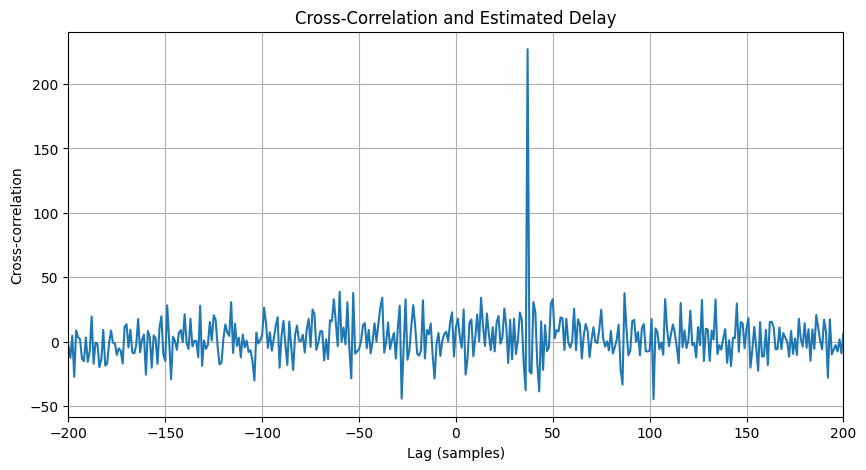

Estimated distance: 12.690999999999999 metres


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Generate transmitted signal
rng = np.random.default_rng(1)

fs = 1000
x = rng.standard_normal(500)

# Introduce a delay of 37 samples
true_delay = 37

y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]
y = y + 0.5*rng.standard_normal(500)

# Calculate cross-correlation
r = signal.correlate(y, x, mode="full")

# Calculate corresponding lags
lags = signal.correlation_lags(len(y), len(x), mode="full")

# Estimate delay
estimated_delay = lags[np.argmax(r)]

print("Actual delay:", true_delay, "samples")
print("Estimated delay:", estimated_delay, "samples")

# Plot cross-correlation
plt.figure(figsize=(10, 5))
plt.plot(lags, r)
plt.xlim(-200, 200)
plt.xlabel("Lag (samples)")
plt.ylabel("Cross-correlation")
plt.title("Cross-Correlation and Estimated Delay")
plt.grid()
plt.show()

# Convert delay into distance
speed_of_sound = 343
distance = estimated_delay / fs * speed_of_sound

print("Estimated distance:", distance, "metres")

In [5]:
# Test different noise levels
noise_levels = [0.5, 1, 2, 4]

for noise_std in noise_levels:

    rng = np.random.default_rng(1)

    noisy_y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500]
    noisy_y = noisy_y + noise_std*rng.standard_normal(500)

    correlation = signal.correlate(noisy_y, x, mode="full")
    estimated_lags = signal.correlation_lags(
        len(noisy_y), len(x), mode="full"
    )

    delay = estimated_lags[np.argmax(correlation)]

    print(
        "Noise:", noise_std,
        "| Estimated delay:", delay,
        "samples"
    )

Noise: 0.5 | Estimated delay: 37 samples
Noise: 1 | Estimated delay: 0 samples
Noise: 2 | Estimated delay: 0 samples
Noise: 4 | Estimated delay: 0 samples


### Observation

Cross-correlation was used to estimate the time delay between the transmitted signal and the received signal.

The actual delay introduced into the signal was 37 samples. At a noise level of 0.5, the estimated delay was also 37 samples, showing that the method successfully detected the correct delay.

When the noise level increased to 1, 2, and 4, the estimated delay became 0 samples. This means that the estimation failed because the noise affected the similarity between the transmitted and received signals.

The experiment shows that cross-correlation can estimate signal delays accurately when the noise level is low, but its accuracy decreases when the noise becomes too high.

The estimated distance was calculated using the speed of sound (343 m/s) and the estimated delay.

Direct recursion:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Using lfilter:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Theoretical response:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Direct recursion matches lfilter: True
lfilter matches theoretical response: True


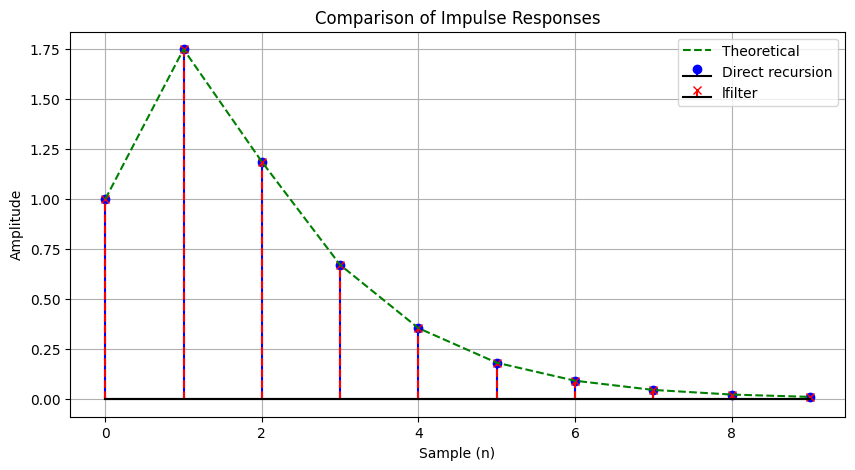

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Difference equation:
# y(n) = 0.75y(n-1) - 0.125y(n-2) + x(n) + x(n-1)

N = 10

# Create impulse input
x = np.zeros(N)
x[0] = 1

# Calculate impulse response using direct recursion
h_direct = np.zeros(N)

for n in range(N):
    x_n = x[n]
    x_previous = x[n-1] if n >= 1 else 0
    y_previous = h_direct[n-1] if n >= 1 else 0
    y_previous2 = h_direct[n-2] if n >= 2 else 0

    h_direct[n] = (
        0.75*y_previous
        - 0.125*y_previous2
        + x_n
        + x_previous
    )

# Calculate using lfilter
h_filter = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    x
)

# Calculate theoretical impulse response
n = np.arange(N)
h_theoretical = 6*(0.5**n) - 5*(0.25**n)

# Display results
print("Direct recursion:")
print(h_direct)

print("\nUsing lfilter:")
print(h_filter)

print("\nTheoretical response:")
print(h_theoretical)

print("\nDirect recursion matches lfilter:",
      np.allclose(h_direct, h_filter))

print("lfilter matches theoretical response:",
      np.allclose(h_filter, h_theoretical))

# Plot impulse responses
plt.figure(figsize=(10, 5))
plt.stem(n, h_direct, linefmt='b-', markerfmt='bo',
         basefmt='k-', label='Direct recursion')
plt.stem(n, h_filter, linefmt='r--', markerfmt='rx',
         basefmt='k-', label='lfilter')
plt.plot(n, h_theoretical, 'g--', label='Theoretical')
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.title("Comparison of Impulse Responses")
plt.legend()
plt.grid()
plt.show()

Step response:
[1.         2.75       3.9375     4.609375   4.96484375 5.14746094
 5.23999023 5.28656006 5.30992126 5.32162094]

Final theoretical value H(1): 5.333333333333333
Last step response value: 5.321620941162109


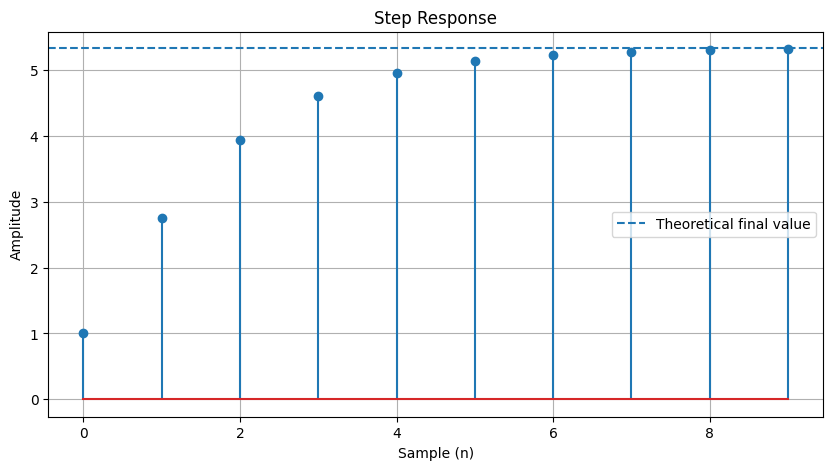

In [7]:
# Create a unit step input
step_input = np.ones(N)

# Calculate step response using lfilter
step_response = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    step_input
)

# Calculate theoretical final value H(1)
final_value = (1 + 1) / (1 - 0.75 + 0.125)

print("Step response:")
print(step_response)

print("\nFinal theoretical value H(1):", final_value)
print("Last step response value:", step_response[-1])

# Plot step response
plt.figure(figsize=(10, 5))
plt.stem(np.arange(N), step_response)
plt.axhline(final_value, linestyle="--",
            label="Theoretical final value")
plt.xlabel("Sample (n)")
plt.ylabel("Amplitude")
plt.title("Step Response")
plt.legend()
plt.grid()
plt.show()

### Observation

The step response was calculated using the lfilter function with a unit step input.

The output increased gradually as the system responded to the continuous input.

The theoretical final value was calculated using:

H(1) = (1 + 1) / (1 - 0.75 + 0.125)

H(1) = 5.3333

The step response approaches the theoretical final value as time increases.

This shows that the system has a finite steady-state output.

## CHECKPOINT 3

### Task 3.3: Linearity and Time-Invariance Results

The following results were obtained:

| System | Linear | Time-Invariant |
|---|---|---|
| x^2 | False | True |
| n x(n) | True | False |
| Moving Average | True | True |

The moving average system was the only system that satisfied both linearity and time-invariance properties.

### Task 3.5: Impulse Response Comparison

Three impulse responses were calculated using:

1. Direct recursion using a for loop.
2. The `signal.lfilter()` function.
3. The theoretical impulse response equation.

All three methods produced matching results. This confirms that the difference equation was implemented correctly.

## ANALYSIS QUESTIONS

### Question 1: Why is np.convolve faster than the double-loop implementation? How many multiplications are required?

The `np.convolve()` function is faster because it uses optimized numerical operations implemented in compiled code, while the custom convolution function uses Python loops.

For two input sequences of lengths L and M, direct convolution requires approximately L × M multiplications.

Therefore, the double-loop implementation becomes slower when the input sequences are very large.

### Question 2: Which systems in Task 3.3 are LTI? Could you predict the results without running the code?

The moving average system is the only LTI system among the three tested systems.

The x^2 system is non-linear because it does not satisfy the linearity property.

The n x(n) system is linear but time-varying because its output depends on the time index n.

The moving average system is both linear and time-invariant.

Yes, these results can be predicted by applying the mathematical definitions of linearity and time invariance.

### Question 3: Give two engineering applications of cross-correlation in Tanzania.

1. Water pipe leak detection: Cross-correlation can compare signals recorded by sensors placed along water pipes to estimate the time difference between signals and help locate water leaks.

2. Radar systems at airports: Cross-correlation can be used to compare transmitted and received signals to estimate the delay and determine the distance of an aircraft from the radar system.

### Question 4: Is the system in Task 3.5 FIR or IIR? Is it stable? Explain.

The system is an Infinite Impulse Response (IIR) system because it uses feedback from previous output samples.

The system is stable because its poles are 0.5 and 0.25, which are both inside the unit circle.

Its impulse response gradually decreases towards zero as the sample number increases.

Therefore, the system is a stable IIR system.

## AI USE STATEMENT

I used ChatGPT as a learning assistant during this laboratory exercise. It helped me understand digital signal processing concepts, explain Python code, interpret results, and organize my observations and analysis answers.

I ran the Python code in Google Colab and reviewed the outputs to understand the practical activities.